### Vorverarbeitung der Daten

,date,KWH,kwh,meters
0,2011-11-23 09:00:00,0.569000,0.284500,2
1,2011-11-23 09:30:00,0.561000,0.280500,2
2,2011-11-23 10:00:00,0.920000,0.153333,6
3,2011-11-23 10:30:00,0.588000,0.098000,6
4,2011-11-23 11:00:00,0.772000,0.110286,7
...,...,...,...,...
40400,2014-02-27 22:00:00,1494.603000,0.299760,4986
40401,2014-02-27 22:30:00,1422.109001,0.285163,4987
40402,2014-02-27 23:00:00,1258.090000,0.252274,4987
40403,2014-02-27 23:30:00,1073.622001,0.215284,4987


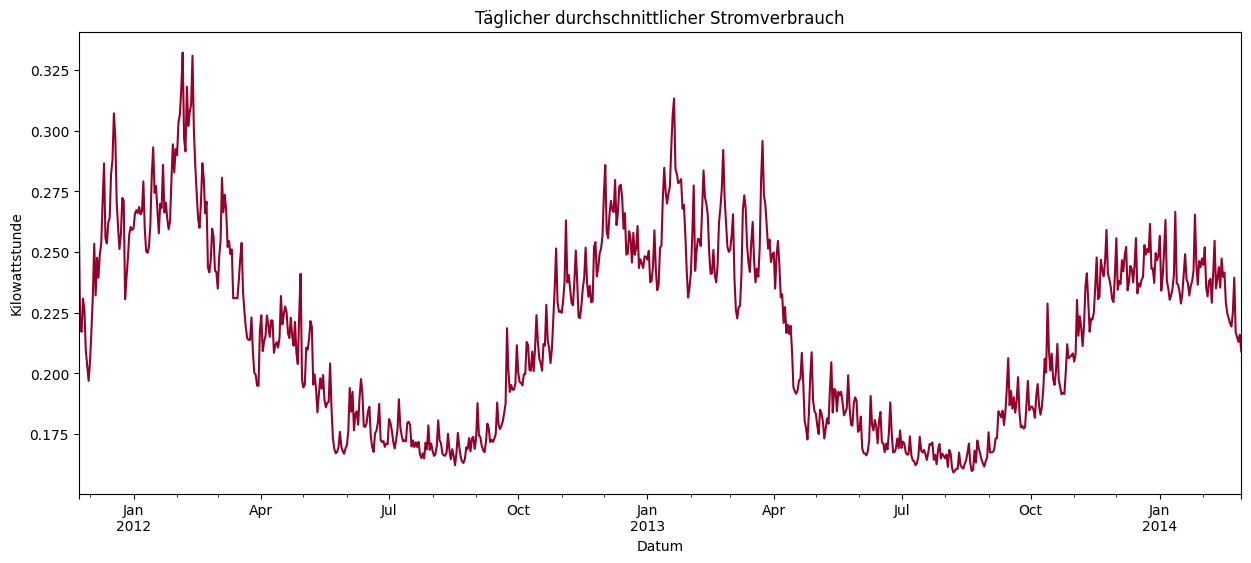

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as skl
import statsmodels.api as sm

df = pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["DateTime"])

# Tarife werden vorerst zusammengelegt
df = df.groupby("date", as_index=False).agg({
    "KWH": "sum",
    "meters": "sum"
}).reset_index()

# Stromverbrauch eines Verbrauchers jedes Zeitpunktes
df["kwh"] = df["KWH"] / df["meters"]

df = df[["date", "KWH", "kwh", "meters"]]
display(df)

# Erste Visualisierung des Datensatzes als täglicher Durchschnittsverbrauch
series = df.set_index("date")["kwh"].sort_index()
series = series.resample("D").mean()
fig, ax = plt.subplots(figsize=(15, 6))
series.plot(ax=ax, color="#96002A")
ax.set(
    title="Täglicher durchschnittlicher Stromverbrauch",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
plt.show()

### Datenbereinigung

,date,KWH,kwh,meters
18781,2012-12-18 15:13:26,0.0,NaN,0
18782,2012-12-18 15:13:27,0.0,NaN,0
18783,2012-12-18 15:13:28,0.0,NaN,0
18784,2012-12-18 15:13:29,0.0,NaN,0
18785,2012-12-18 15:13:30,0.0,NaN,0
...,...,...,...,...
29001,2013-07-05 12:54:31,0.0,NaN,0
29003,2013-07-05 13:15:05,0.0,NaN,0
32710,2013-09-20 18:24:09,0.0,NaN,0
34566,2013-10-29 09:33:01,0.0,NaN,0


0


,kwh
date,
2011-11-23 09:00:00,0.284500
2011-11-23 09:30:00,0.280500
2011-11-23 10:00:00,0.153333
2011-11-23 10:30:00,0.098000
2011-11-23 11:00:00,0.110286
...,...
2014-02-27 22:00:00,0.299760
2014-02-27 22:30:00,0.285163
2014-02-27 23:00:00,0.252274


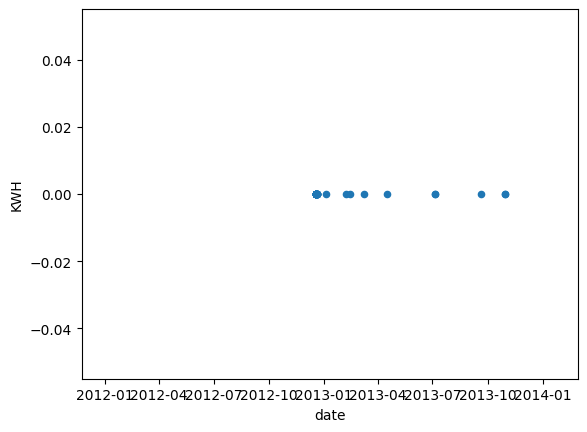

In [28]:
display(df.loc[df["KWH"] == 0])
ax = df.loc[df["KWH"] == 0].plot.scatter(x="date", y="KWH")
ax.set_xlim(df["date"].min(), df["date"].max())

prev = df["kwh"].count()
df = df[
    (df["date"].dt.minute % 30 == 0) &
    (df["date"].dt.second == 0)
]
print(prev - df["kwh"].count())

# https://pandas.pydata.org/docs/user_guide/timeseries.html#timeseries-offset-aliases
df = df.set_index("date")[["kwh"]].sort_index().asfreq("30min")
df

# Alternativ
# df = df.dropna()

### Untersuchung der Zeitreihe

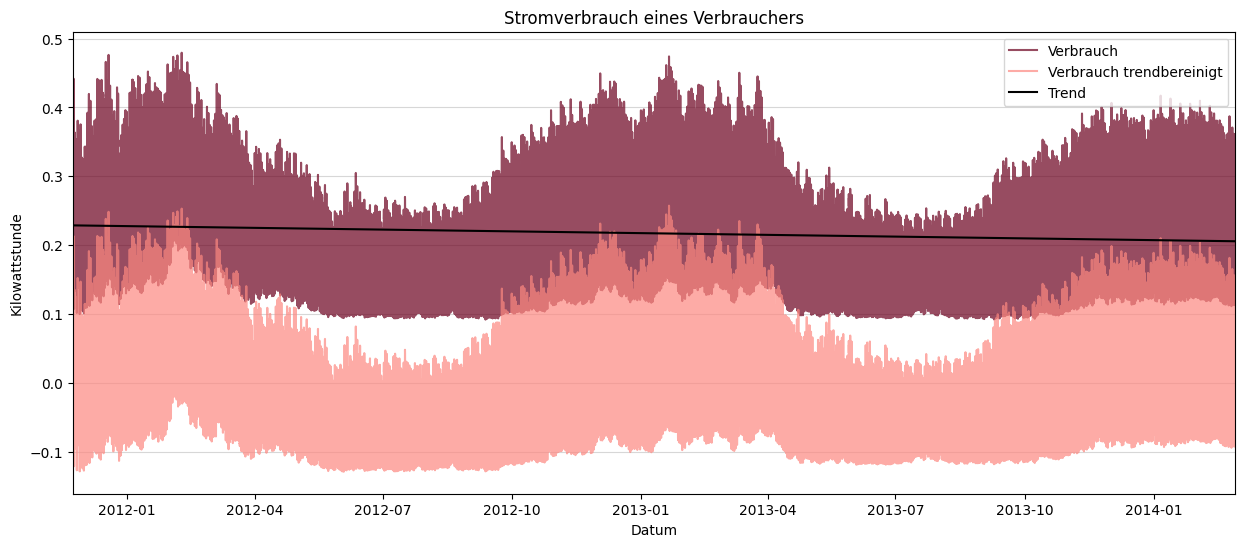

In [29]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)

x = mdates.date2num(df.index)
p = np.poly1d(np.polyfit(x, df["kwh"], 1))
df["kwh_trend"] = p(x)

df["kwh_trendbereinigt"] = df["kwh"] -  df["kwh_trend"]
ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.7, label="Verbrauch")
ax.plot(df.index, df["kwh_trendbereinigt"], color="#FD8880", alpha=0.7, label="Verbrauch trendbereinigt")
ax.plot(df.index, df["kwh_trend"], color="#000000", alpha=1, label="Trend")
ax.set(
    title="Stromverbrauch eines Verbrauchers",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.legend()
ax.grid(True, axis="y", alpha=0.5)
plt.show()

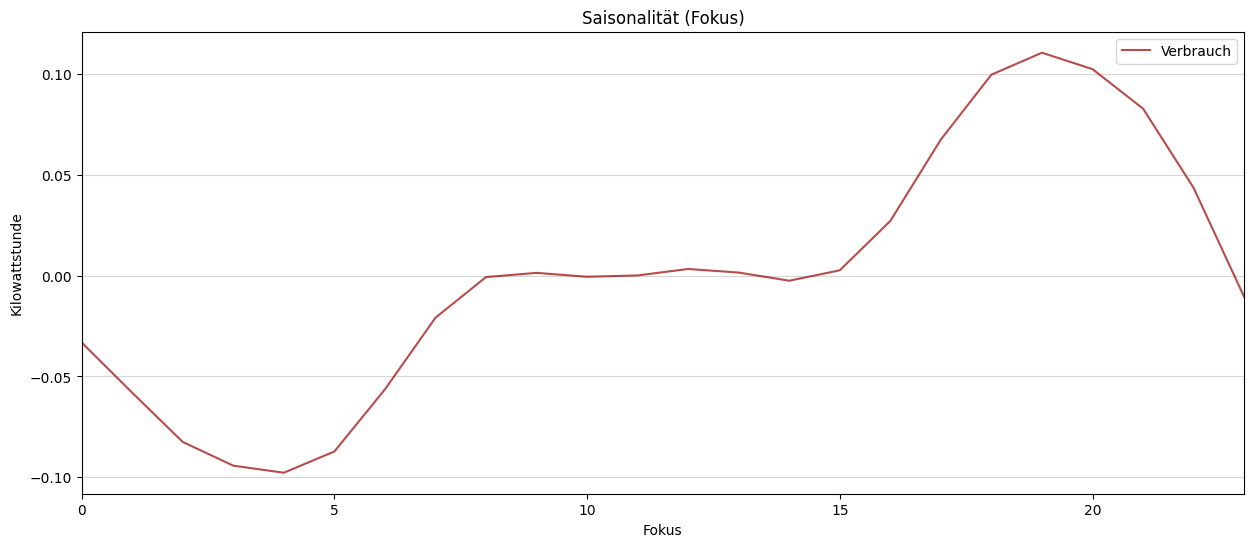

,kwh,kwh_trend,kwh_trendbereinigt,focus,kwh_trendbereinigt_focus
0,0.284500,0.228705,0.055795,9,0.001426
1,0.280500,0.228705,0.051795,9,0.001426
2,0.153333,0.228704,-0.075371,10,-0.000503
3,0.098000,0.228703,-0.130703,10,-0.000503
4,0.110286,0.228703,-0.118417,11,0.000158
...,...,...,...,...,...
39722,0.299760,0.205637,0.094122,22,0.043623
39723,0.285163,0.205637,0.079526,22,0.043623
39724,0.252274,0.205636,0.046638,23,-0.010481
39725,0.215284,0.205636,0.009648,23,-0.010481


In [30]:
# .hour, .dayofweek, .day
df["focus"] = df.index.hour

seasonal = df.groupby("focus")["kwh_trendbereinigt"].mean()

fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)

seasonal.plot(ax=ax, color="#9B0000", alpha=0.7, label="Verbrauch")
ax.set(
    title="Saisonalität (Fokus)",
    xlabel="Fokus",
    ylabel="Kilowattstunde",
)
ax.legend()
ax.grid(True, axis="y", alpha=0.5)
plt.show()

df = pd.merge(df, seasonal, on="focus", suffixes=("", "_focus"))
df

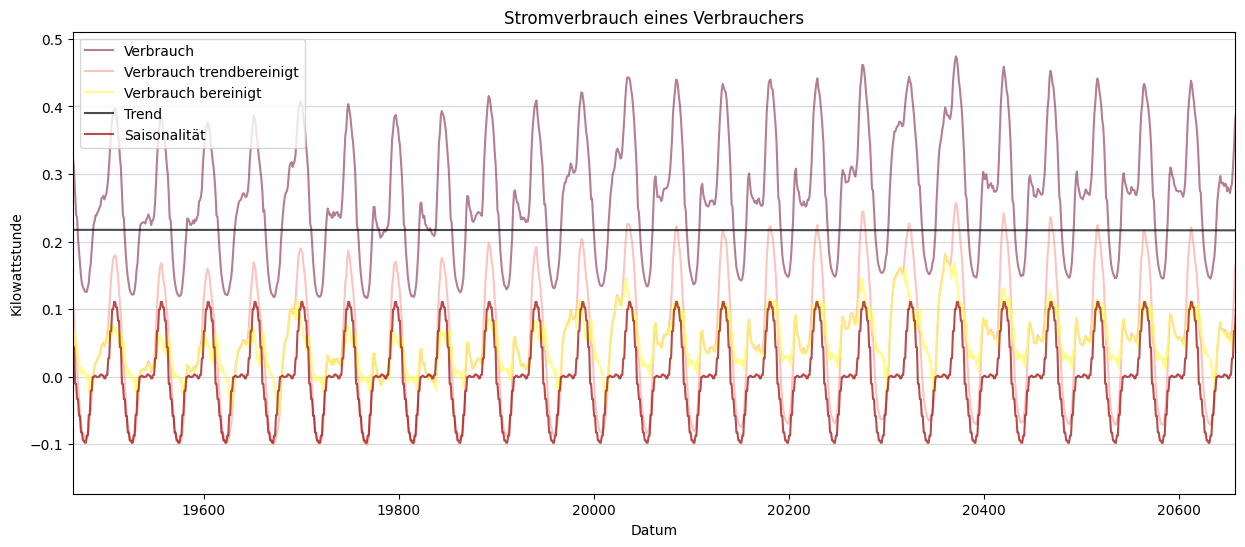

In [31]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)

df["kwh_bereinigt"] = df["kwh_trendbereinigt"] - df["kwh_trendbereinigt_focus"]
ax.plot(df.index, df["kwh"], color="#6B001E", alpha=0.5, label="Verbrauch")
ax.plot(df.index, df["kwh_trendbereinigt"], color="#FD8880", alpha=0.5, label="Verbrauch trendbereinigt")
ax.plot(df.index, df["kwh_bereinigt"], color="#FFFC58", alpha=0.7, label="Verbrauch bereinigt")
ax.plot(df.index, df["kwh_trend"], color="#000000FF", alpha=0.7, label="Trend")
ax.plot(df.index, df["kwh_trendbereinigt_focus"], color="#9B0000", alpha=0.7, label="Saisonalität")
ax.set(
    title="Stromverbrauch eines Verbrauchers",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.set_xlim(pd.Series(df.index).quantile(0.49), pd.Series(df.index).quantile(0.52))
ax.legend()
ax.grid(True, axis="y", alpha=0.5)
plt.show()

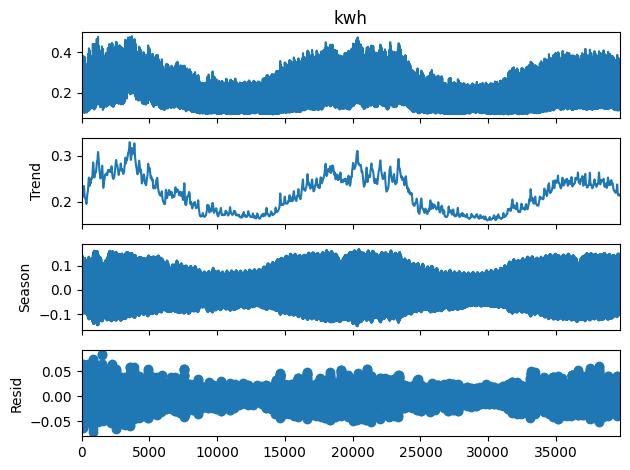

In [ ]:
# from statsmodels.tsa.seasonal import STL

# decomposition = STL(
#     df["kwh"],
#     period=48  # 48 = Tag, 336 = Woche
# )
# decomposition = decomposition.fit()
# _ = decomposition.plot()

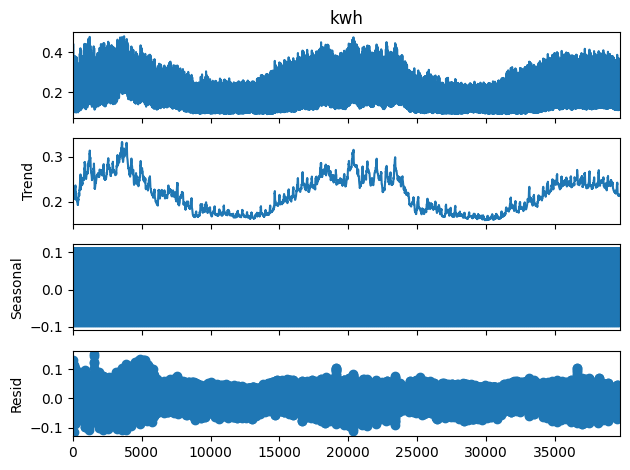

In [32]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    df["kwh"],
    model="additive",
    period=48
)
_ = decomposition.plot()

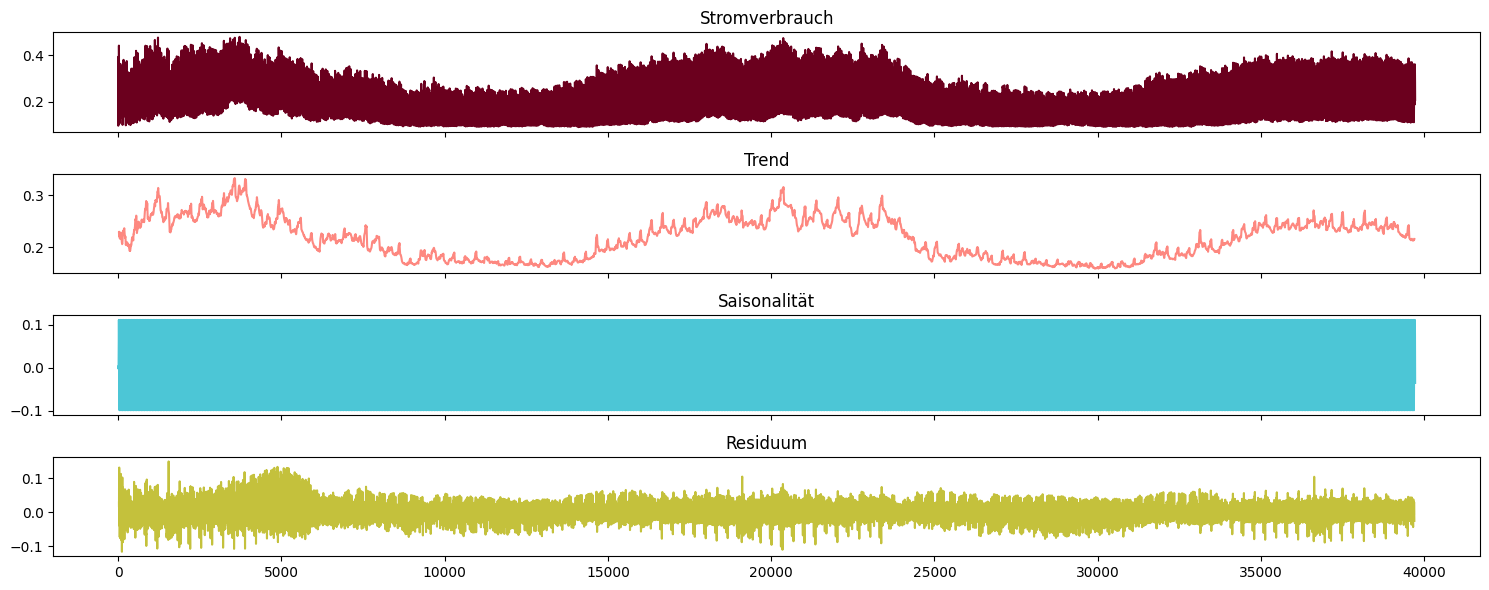

In [33]:
trend = decomposition.trend
seasonal = decomposition.seasonal
resid = decomposition.resid

fig, ax = plt.subplots(4, 1, figsize=(15,6), sharex=True)

ax[0].plot(df["kwh"], color="#6B001E")
ax[0].set_title("Stromverbrauch")

ax[1].plot(trend, color="#FD8880")
ax[1].set_title("Trend")

ax[2].plot(seasonal, color="#00AEC5", alpha=0.7)
ax[2].set_title("Saisonalität")

ax[3].plot(resid, color="#C4C13C")
ax[3].set_title("Residuum")

plt.tight_layout()
plt.show()

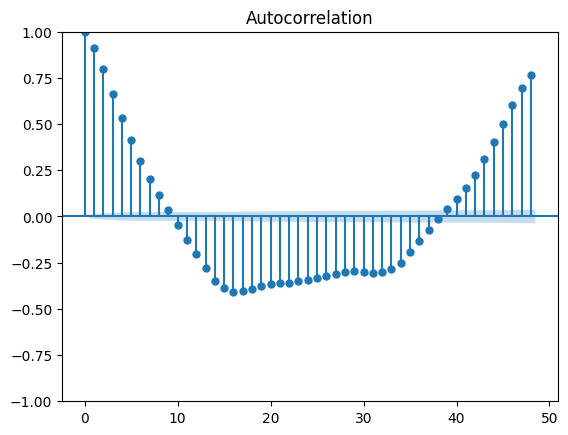

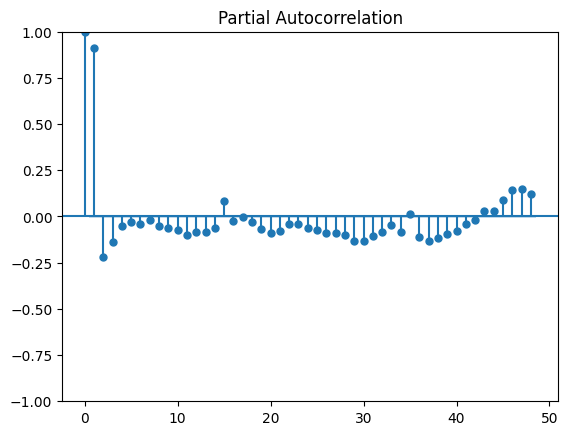

In [33]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

_ = plot_acf(resid.dropna(), lags=48)
# _ = plot_acf(df["kwh_bereinigt"].dropna(), lags=48)
_ = plot_pacf(resid.dropna(), lags=48)

### Vorhersage

In [34]:
from sklearn.linear_model import LinearRegression

# Drop rows with NaN values in the relevant columns for regression
df_x = df.copy()
df_x['U_bereinigt_t-1'] = df_x.kwh_bereinigt.shift(1)
df_x['U_bereinigt_t-2'] = df_x.kwh_bereinigt.shift(2)
df_x['U_bereinigt_t-3'] = df_x.kwh_bereinigt.shift(3)
h_reg = df_x.dropna(subset=['kwh_bereinigt', 'U_bereinigt_t-1', 'U_bereinigt_t-2', 'U_bereinigt_t-3']).copy()

# Define independent variables (X) and dependent variable (y)
X = h_reg[['U_bereinigt_t-1', 'U_bereinigt_t-2', 'U_bereinigt_t-3']]
y = h_reg['kwh_bereinigt']

# Initialize and fit the linear regression model
model = LinearRegression()
model.fit(X, y)

# Predict the values
h_reg['U_bereinigt_pred'] = model.predict(X)

# Merge the predictions back into the original 'h' DataFrame using 'Zeitp' for alignment.
# Note: This will create a new 'U_bereinigt_pred' column in 'h' and will have NaN for rows not in h_reg.
h = pd.merge(df, h_reg['U_bereinigt_pred'], left_index=True, right_index=True)

print("Regression Coefficients:", model.coef_)
print("Regression Intercept:", model.intercept_)
h

Regression Coefficients: [ 0.6895241   0.59082521 -0.32792824]
Regression Intercept: 2.41132433952919e-06


,kwh,kwh_trend,kwh_trendbereinigt,focus,kwh_trendbereinigt_focus,kwh_bereinigt,U_bereinigt_pred
3,0.098000,0.228703,-0.130703,10,-0.000503,-0.130200,-0.039690
4,0.110286,0.228703,-0.118417,11,0.000158,-0.118575,-0.150525
5,0.193000,0.228702,-0.035702,11,0.000158,-0.035860,-0.134132
6,0.394222,0.228702,0.165521,12,0.003356,0.162165,-0.052085
7,0.304100,0.228701,0.075399,12,0.003356,0.072043,0.129516
...,...,...,...,...,...,...,...
39722,0.299760,0.205637,0.094122,22,0.043623,0.050500,0.036727
39723,0.285163,0.205637,0.079526,22,0.043623,0.035904,0.038103
39724,0.252274,0.205636,0.046638,23,-0.010481,0.057119,0.044384
39725,0.215284,0.205636,0.009648,23,-0.010481,0.020130,0.044040


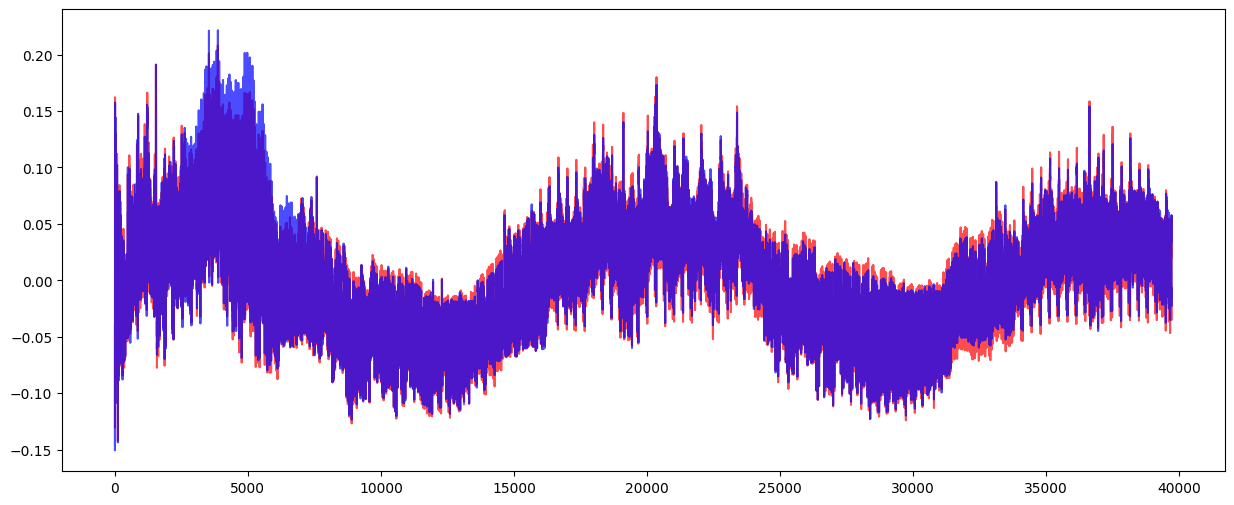

In [35]:
plt.figure(figsize=(15,6))
plt.plot(h.kwh_bereinigt, alpha=0.7, color="red")
plt.plot(h.U_bereinigt_pred, alpha=0.7, color="blue")

In [52]:
from statsmodels.tsa.arima.model import ARIMA

# TODO
model = ARIMA(df["kwh"], order=(2,1,2)).fit()
forecast = model.forecast(steps=12)

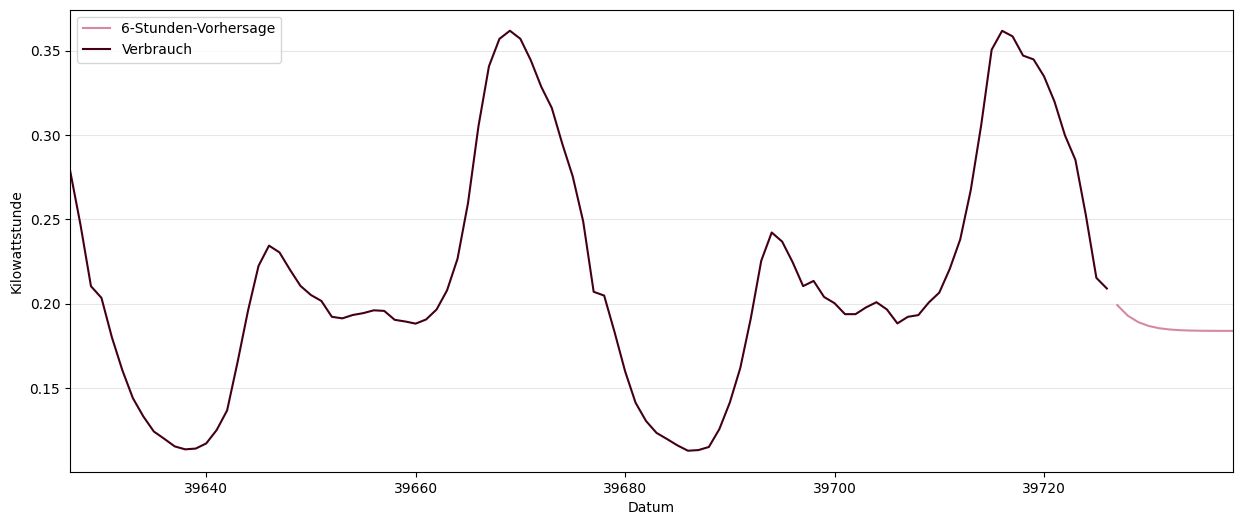

In [ ]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.margins(x=0)

ax.plot(forecast.index, forecast, color="#A5002F75", label="6-Stunden-Vorhersage")
df["kwh"].tail(100).plot(ax=ax, color="#440013", label="Verbrauch")
ax.set(
    title="",
    xlabel="Datum",
    ylabel="Kilowattstunde",
)
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.show()

In [ ]:
df_new = df.copy()
df_new["trend"] = decomposition.trend
df_new["seasonal"] = decomposition.seasonal
df_new["resid"] = decomposition.resid

varianzen = df_new[["kwh", "trend", "seasonal", "resid"]].var()
varianzen["rythmus"] = decomposition.seasonal.var()
varianzen
varianz_anteile = varianzen/varianzen["kwh"]
varianz_anteile

print("Von der Varianz der Zeitreihe werden %2.1f%% durch den Trend erklärt, , %2.1f%% durch die tägliche Periodizität und %2.1f%% haben andere Ursachen." %
 ((100.0*varianz_anteile.trend),
   (100.0*varianz_anteile.rythmus),
   (100.0*varianz_anteile.resid)))


Von der Varianz der Zeitreihe werden 25.4% durch den Trend erklärt, Period. 63.2% und 11.2% haben andere Ursachen.
